# Import Required Libraries

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
cd /content/drive/MyDrive/Machine learning 2024/Notebooks - ANN - DNN/11.Auto encoder/Denoising brain tumor project

/content/drive/MyDrive/Machine learning 2024/Notebooks - ANN - DNN/11.Auto encoder/Denoising brain tumor project


In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Conv2D, Conv2DTranspose, Input, MaxPooling2D, UpSampling2D
from tensorflow.keras.optimizers import Adam

# Load Data

In [4]:
root_dir = "dataset/"

In [5]:
image_paths = os.listdir(root_dir)
len(image_paths)

100

In [ ]:
ls

best_model.weights.h5  dataset/  image-denoising.ipynb


In [ ]:
images = []

for image_path in image_paths:
    img = load_img(root_dir + image_path, target_size=(160, 160), color_mode="grayscale")
    img = img_to_array(img)
    img = img / 255.
    images.append(img)

In [7]:
images = np.array(images)

In [8]:
type(images)

numpy.ndarray

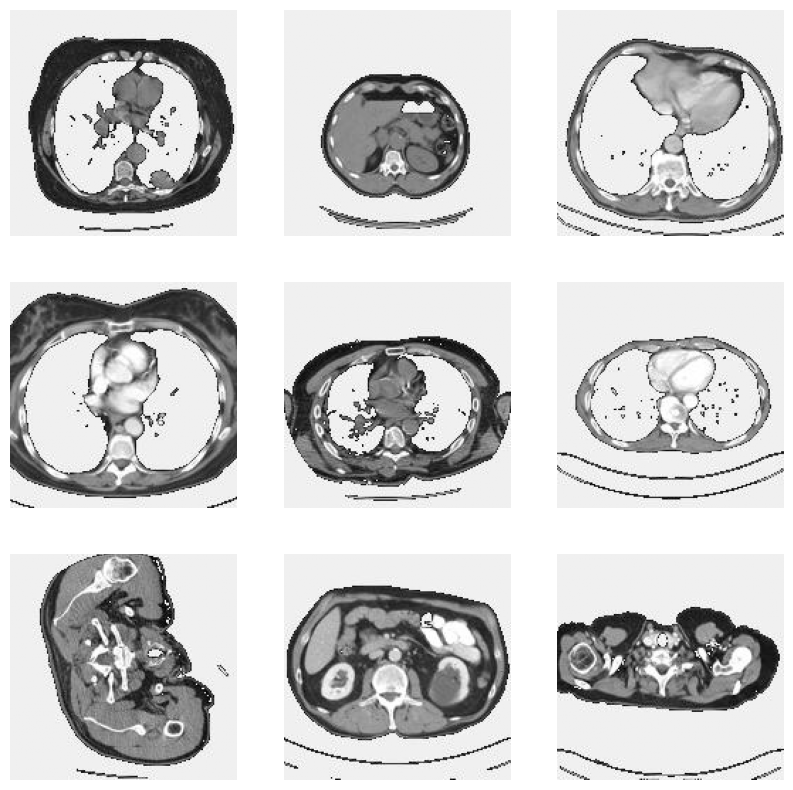

In [ ]:
# plot some images

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(images[i].reshape(160, 160), cmap='gray')
    plt.axis('off')
plt.show()


In [ ]:
# Set the intensity of the noise to be added to the images
noise_factor = 0.1

# Initialize an empty list to store the processed noisy images
noise_images = []

for image in images:
    # Add Gaussian noise to the image:
    # 1. np.random.randn generates random noise with the same shape as the input image
    # 2. Multiply by noise_factor to control the strength of the noise
    noisy = image + noise_factor * np.random.randn(*image.shape)

    # Clip the pixel values to ensure they stay within the valid range [0.0, 1.0]
    # This prevents values from exceeding 1 or dropping below 0 after adding noise
    noisy = np.clip(noisy, 0., 1.)

    # Append the resulting noisy image to the list
    noise_images.append(noisy)

np.clip(noisy, 0., 1.) limits (or "clips") the values of the noisy image array.
If any value in the noisy array is less than 0., it will be set to 0..
If any value in the noisy array is greater than 1., it will be set to 1..

In [ ]:
noise_images = np.array(noise_images)

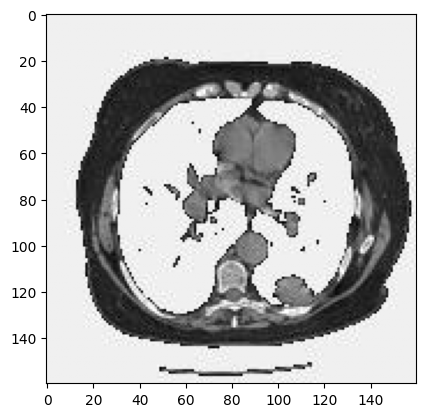

In [ ]:
plt.imshow(images[0], cmap="gray")

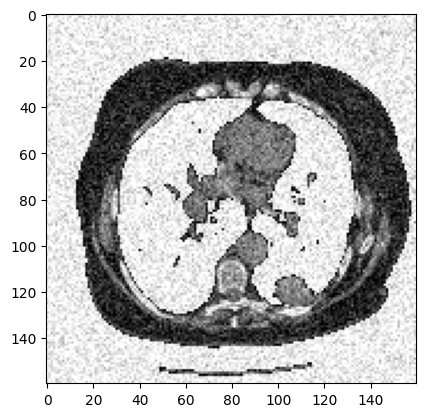

In [ ]:
plt.imshow(noise_images[0], cmap="gray")

In [ ]:
noise_train = noise_images[:80]
noise_test = noise_images[80:]

noise_train.shape, noise_test.shape

((80, 160, 160, 1), (20, 160, 160, 1))

In [ ]:
normal_train = images[:80]
normal_test = images[80:]

normal_train.shape, normal_test.shape

((80, 160, 160, 1), (20, 160, 160, 1))

# Models

In [ ]:
from keras.models import Sequential, Model
from keras.layers import Dense, Conv2D, MaxPooling2D,MaxPool2D ,UpSampling2D, Flatten, Input
from keras.optimizers import SGD, Adam, Adadelta, Adagrad
from keras import backend as K

In [ ]:
def autoencoder():

    input_img = Input(shape=(160,160,1), name='image_input')

    #enoder
    x = Conv2D(128, (3,3), activation='relu', padding='same', name='Conv1')(input_img)
    x = MaxPooling2D((2,2), padding='same', name='pool1')(x)
    x = Conv2D(64, (3,3), activation='relu', padding='same', name='Conv2')(x)
    x = MaxPooling2D((2,2), padding='same', name='pool2')(x)   #32

    #decoder
    x = Conv2D(64, (3,3), activation='relu', padding='same', name='Conv3')(x)
    x = UpSampling2D((2,2), name='upsample1')(x)
    x = Conv2D(128, (3,3), activation='relu', padding='same', name='Conv4')(x)
    x = UpSampling2D((2,2), name='upsample2')(x)
    x = Conv2D(1, (3,3), activation='sigmoid', padding='same', name='Conv5')(x)

    #model
    autoencoder = Model(inputs=input_img, outputs=x)
    autoencoder.compile(optimizer='adam', loss='binary_crossentropy')

    return autoencoder

In [ ]:
model= autoencoder()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_input (InputLayer)        │ (None, 160, 160, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1 (Conv2D)                  │ (None, 160, 160, 128)  │         1,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 80, 80, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv2 (Conv2D)                  │ (None, 80, 80, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv3 (Conv2D)                  │ (None, 40, 40, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ upsample1 (UpSampling2D)        │ (None, 80, 80, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv4 (Conv2D)                  │ (None, 80, 80, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ upsample2 (UpSampling2D)        │ (None, 160, 160, 128)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv5 (Conv2D)                  │ (None, 160, 160, 1)    │         1,153 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 187,009 (730.50 KB)

 Trainable params: 187,009 (730.50 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

# 1. Checkpoint: Save the best model
checkpoint_callback = ModelCheckpoint(
    filepath='best_model.weights.h5',
    save_weights_only=True,
    monitor='val_loss',
    mode='min',
    save_best_only=True
)

# 2. EarlyStopping: Stop training when val_loss stops improving
early_stopping_callback = EarlyStopping(
    monitor='val_loss',
    patience=10,           # Number of epochs to wait for improvement
    restore_best_weights=True,
    verbose=1
)

# 3. ReduceLROnPlateau: Reduce learning rate when learning stagnates
reduce_lr_callback = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,            # Factor by which the learning rate will be reduced (new_lr = lr * factor)
    patience=5,            # Number of epochs with no improvement before reducing LR
    min_lr=1e-6,
    verbose=1
)

In [ ]:
model.fit(noise_train,
                 normal_train,
                 validation_data=(noise_test, normal_test),
                 epochs=500,
                 batch_size=8,
                 callbacks=[checkpoint_callback, early_stopping_callback, reduce_lr_callback])

Epoch 1/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 12s 426ms/step - loss: 0.5749 - val_loss: 0.5348 - learning_rate: 0.0010
Epoch 2/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - loss: 0.4953 - val_loss: 0.4576 - learning_rate: 0.0010
Epoch 3/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.4323 - val_loss: 0.4308 - learning_rate: 0.0010
Epoch 4/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step - loss: 0.4129 - val_loss: 0.4151 - learning_rate: 0.0010
Epoch 5/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.4075 - val_loss: 0.4087 - learning_rate: 0.0010
Epoch 6/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.4016 - val_loss: 0.4028 - learning_rate: 0.0010
Epoch 7/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.3958 - val_loss: 0.4003 - learning_rate: 0.0010
Epoch 8/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.3923 - val_loss: 0.3993 - learning_rate: 0.0010
Epoch 9/500
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step - loss: 0.3903 - val_loss: 0.3964 - learning_rate: 0.0010
Epoch 10

In [ ]:
predicted = model.predict(noise_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


In [ ]:
from sklearn.metrics import mean_squared_error
# Calculate Mean Squared Error (MSE)
actual_values_flat = normal_test.flatten()
predicted_values_flat = predicted.flatten()

mse = mean_squared_error(actual_values_flat, predicted_values_flat)

print("Mean Squared Error:", mse)

Mean Squared Error: 0.006505185272544622


In [ ]:
evaluation = model.evaluate(noise_test, normal_test)
evaluation

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 352ms/step - loss: 0.3716


0.37163034081459045

In [ ]:
def plot_predictions(test, preds):
    plt.figure(figsize=(12, 10))

    # Noise test
    for i in range(16):
        plt.subplot(4, 8, i + 1)
        plt.imshow(test[i], cmap='gray')
        plt.axis('off')
        plt.title('Noised')

    # Predicted
    for i in range(16):
        plt.subplot(4, 8, i + 17)
        plt.imshow(preds[i], cmap='gray')
        plt.axis('off')
        plt.title('Predicted')

    plt.show()

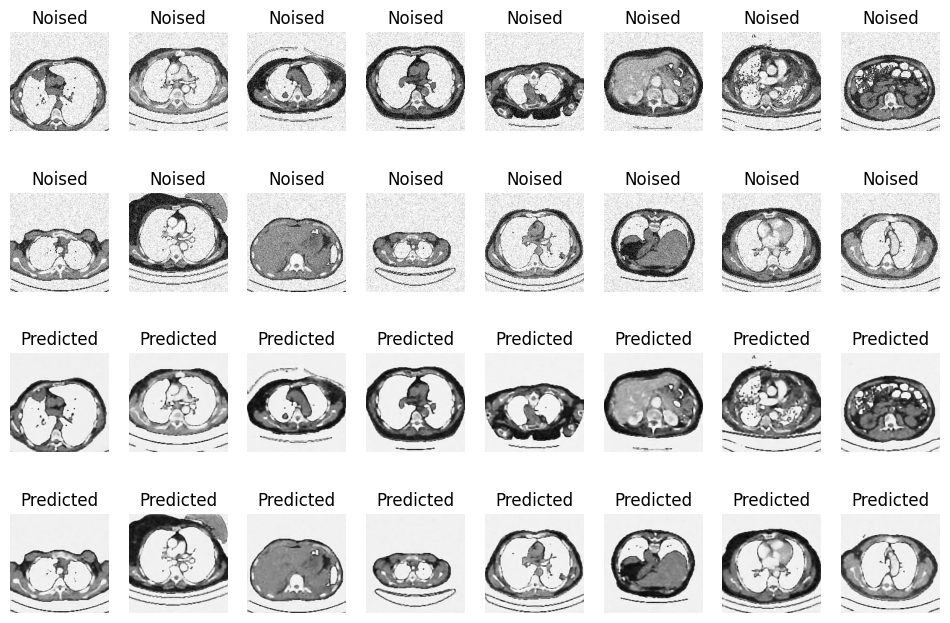

In [ ]:
plot_predictions(noise_test, predicted)

In [ ]:
import numpy as np
from skimage.metrics import peak_signal_noise_ratio

# Calculate PSNR for each pair of clean and denoised images and take the absolute value
psnr_values = [abs(peak_signal_noise_ratio(clean_img, denoised_img, data_range=denoised_img.max() - denoised_img.min())) for clean_img, denoised_img in zip(normal_test, predicted)]

# Calculate the average PSNR
average_psnr = np.mean(psnr_values)

# Print the average PSNR
print("Average PSNR:", average_psnr)


Average PSNR: 21.51219067300612


**PSNR (Peak Signal-to-Noise Ratio)** measures the quality of a denoised image by comparing it to the original clean image. A higher PSNR indicates better image quality (less difference from the original), while a lower PSNR suggests more distortion.